# 서울 지하철 혼잡도 데이터 분석

- 팀원: 20262706 노예은, 20261289 백다은

## 1. 주제 선정 이유

일상생활과 밀접한 지하철 혼잡 문제에 관심을 가지게 되었으며,
호선·시간대·요일에 따른 혼잡도 차이를 파악하고자
이 주제를 선정하였다.

공공데이터를 활용하여 실생활 속 문제를 분석하고,
보다 효율적인 지하철 이용에 도움이 되는 정보를 제공하고자 한다.

## 2. 분석 목적

- 호선별 평균 혼잡도 및 순위 파악
- 시간대별 혼잡도 변화 분석
- 평일과 주말의 혼잡도 차이 비교
- 혼잡도 상위 10개 역의 특징 파악

## 데이터 출처 및 소개

- 데이터 출처: 공공데이터포털
- 제공 기관: 서울교통공사
- 데이터 형식: CSV
- 분석 대상: 서울 지하철 1~8호선
- 주요 항목: 호선, 역번호, 역명, 상하구분, 요일, 시간대별 혼잡도

30분 단위로 제공되는 지하철 혼잡도 데이터를 활용하여 다양한 기준으로 혼잡도를 비교하고 분석하였다.

In [2]:
import pandas as pd

df = pd.read_csv("data/subway_congestion.csv", encoding="cp949")
df.head()

,구분,호선,역번호,역명,상하구분,5시30분,6시00분,6시30분,7시00분,7시30분,...,20시00분,20시30분,21시00분,21시30분,22시00분,22시30분,23시00분,23시30분,00시00분,00시30분
0,평일,1호선,150,서울역,상선,8.9,21.2,22.7,41.3,72.1,...,18.3,17.9,19.3,16.0,16.4,17.2,13.6,8.9,7.1,1.6
1,평일,1호선,150,서울역,하선,11.5,11.2,16.4,22.4,40.2,...,40.5,40.4,42.5,38.6,38.6,31.0,18.6,13.7,9.7,0.0
2,평일,1호선,151,시청,상선,7.3,15.8,18.2,30.6,54.8,...,21.8,22.1,22.3,21.1,20.7,20.0,17.8,10.2,7.5,1.6
3,평일,1호선,151,시청,하선,9.2,10.4,17.0,21.9,36.7,...,36.2,37.8,41.1,31.9,34.5,26.9,17.2,12.7,6.7,0.4
4,평일,1호선,152,종각,상선,6.8,14.6,11.4,20.0,31.9,...,28.2,28.8,30.3,27.7,27.4,26.4,24.4,12.8,8.4,1.5


# 1. 호선별 혼잡도 분석

각 호선의 전체 시간대 평균 혼잡도를 계산하고, 혼잡도가 높은 순서대로 비교하였다.

### 분석 방법

- 호선별 평균 혼잡도 계산
- 평균 혼잡도 순위 비교
- 가장 혼잡한 호선과 한산한 호선 확인
- 가로 막대그래프를 활용한 시각화

In [3]:
# 시간대 컬럼 선택
time_cols = df.columns[5:]

# 각 행의 평균 혼잡도 계산
df["평균혼잡도"] = df[time_cols].mean(axis=1)

# 호선별 평균 혼잡도 계산
line_avg = df.groupby("호선")["평균혼잡도"].mean()

line_avg

호선
1호선    27.233846
2호선    32.877968
3호선    25.958371
4호선    31.203008
5호선    26.869458
6호선    23.836544
7호선    31.615140
8호선    29.650270
Name: 평균혼잡도, dtype: float64

In [4]:
# 평균 혼잡도가 높은 순서로 정렬
line_rank = line_avg.sort_values(ascending=False)

# 소수점 둘째 자리까지 표시
line_rank.round(2)

호선
2호선    32.88
7호선    31.62
4호선    31.20
8호선    29.65
1호선    27.23
5호선    26.87
3호선    25.96
6호선    23.84
Name: 평균혼잡도, dtype: float64

In [5]:
# 가장 혼잡한 호선
print("가장 혼잡한 호선:", line_rank.idxmax())
print("평균 혼잡도:", round(line_rank.max(), 2), "%")

# 가장 한산한 호선
print("가장 한산한 호선:", line_rank.idxmin())
print("평균 혼잡도:", round(line_rank.min(), 2), "%")

가장 혼잡한 호선: 2호선
평균 혼잡도: 32.88 %
가장 한산한 호선: 6호선
평균 혼잡도: 23.84 %


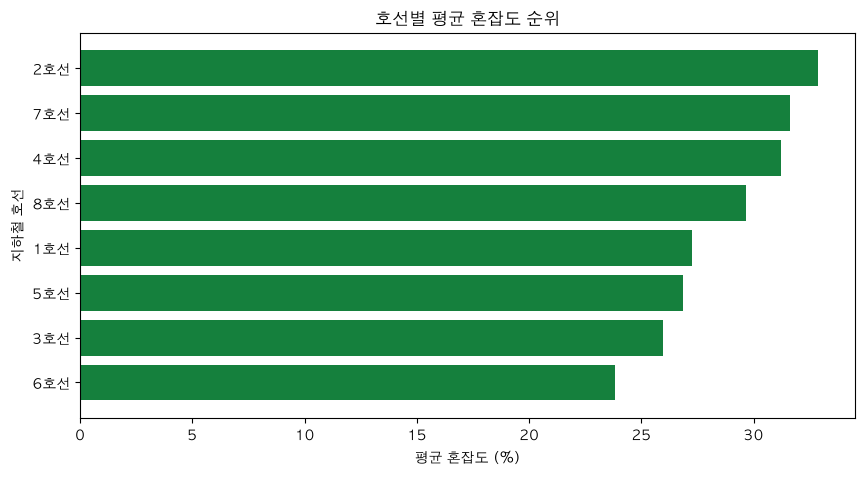

In [6]:
import matplotlib.pyplot as plt

# 맥북 한글 폰트 설정
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

# 평균 혼잡도 높은 순서로 정렬
line_rank = line_avg.sort_values(ascending=False)

# 가로 막대그래프 생성
plt.figure(figsize=(10, 5))

plt.barh(line_rank.index, line_rank.values, color="#15803D")

# 혼잡도가 높은 호선이 위쪽에 오도록 설정
plt.gca().invert_yaxis()

# 그래프 제목 및 축 이름
plt.title("호선별 평균 혼잡도 순위")
plt.xlabel("평균 혼잡도 (%)")
plt.ylabel("지하철 호선")

plt.show()

### 분석 결과

- 2호선의 평균 혼잡도가 가장 높게 나타났다.
- 6호선의 평균 혼잡도가 가장 낮게 나타났다.
- 호선에 따라 평균 혼잡도에 차이가 있음을 확인하였다.

# 2. 시간대별 혼잡도 분석

30분 단위의 평균 혼잡도를 계산하여 하루 동안의 혼잡도 변화와 출퇴근 시간대의 특징을 파악하였다.

### 분석 방법

- 30분 단위 평균 혼잡도 계산
- 평일 출근 시간대와 퇴근 시간대 비교
- 최대 및 최소 혼잡 시간대 확인
- 선그래프와 막대그래프를 활용한 시각화


In [7]:
# 30분 단위 시간대 컬럼 선택
time_cols = df.columns[5:44]

# 시간대별 평균 혼잡도 계산
time_avg = df[time_cols].mean()

# 소수점 둘째 자리까지 출력
time_avg.round(2)

5시30분     16.44
6시00분     16.42
6시30분     16.02
7시00분     21.11
7시30분     27.09
8시00분     34.03
8시30분     32.41
9시00분     32.72
9시30분     31.03
10시00분    29.39
10시30분    29.66
11시00분    30.14
11시30분    30.14
12시00분    30.58
12시30분    33.21
13시00분    33.45
13시30분    33.10
14시00분    32.47
14시30분    33.07
15시00분    34.23
15시30분    36.33
16시00분    38.61
16시30분    40.97
17시00분    42.16
17시30분    41.89
18시00분    42.51
18시30분    39.12
19시00분    32.34
19시30분    28.97
20시00분    27.79
20시30분    28.27
21시00분    28.34
21시30분    27.07
22시00분    27.69
22시30분    24.33
23시00분    20.64
23시30분    14.82
00시00분     4.57
00시30분     1.79
dtype: float64

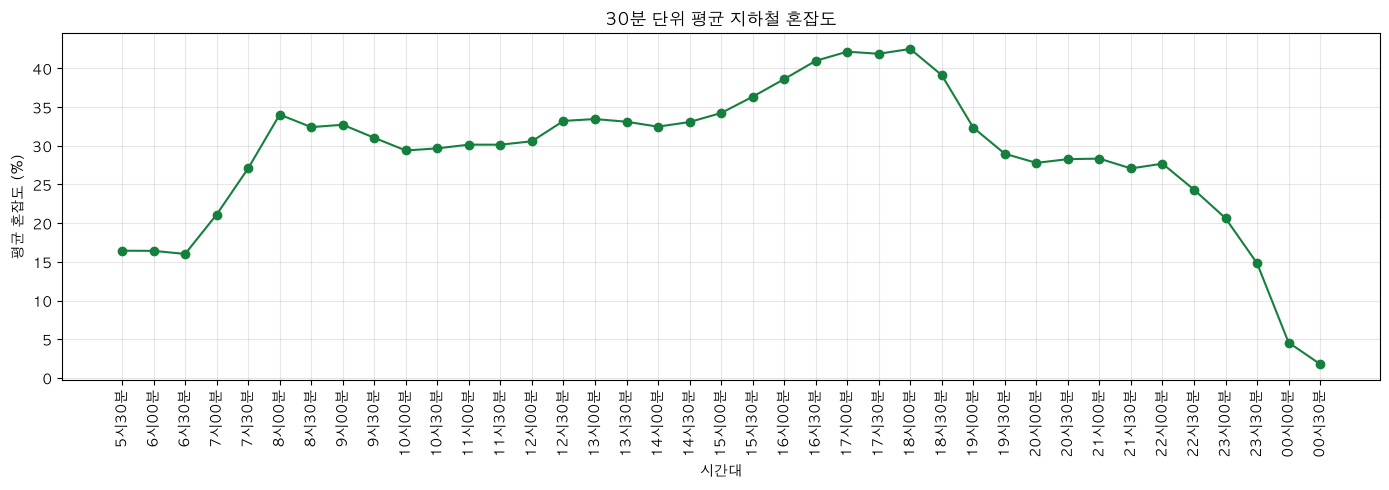

In [8]:
# 30분 단위 평균 혼잡도 선그래프
plt.figure(figsize=(14, 5))
plt.plot(time_avg.index, time_avg.values, marker="o", color="#15803D")

plt.title("30분 단위 평균 지하철 혼잡도")
plt.xlabel("시간대")
plt.ylabel("평균 혼잡도 (%)")

plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# 평일 데이터만 선택
weekday_df = df[df["구분"] == "평일"]

# 출퇴근 시간대 설정
morning_cols = ["7시00분", "7시30분", "8시00분", "8시30분"]
evening_cols = ["18시00분", "18시30분", "19시00분", "19시30분"]

# 출퇴근 평균 혼잡도 계산
morning_avg = weekday_df[morning_cols].mean().mean()
evening_avg = weekday_df[evening_cols].mean().mean()

# 결과 출력
print(f"출근 시간 평균 혼잡도: {morning_avg:.2f}%")
print(f"퇴근 시간 평균 혼잡도: {evening_avg:.2f}%")

출근 시간 평균 혼잡도: 49.04%
퇴근 시간 평균 혼잡도: 46.46%


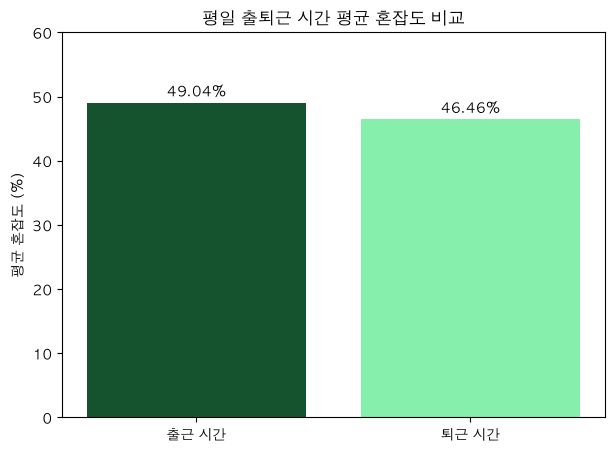

In [10]:
# 출퇴근 혼잡도 비교
labels = ["출근 시간", "퇴근 시간"]
values = [morning_avg, evening_avg]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, values, color=["#14532D", "#86EFAC"])

plt.title("평일 출퇴근 시간 평균 혼잡도 비교")
plt.ylabel("평균 혼잡도 (%)")
plt.ylim(0, 60)

# 막대 위에 평균 혼잡도 표시
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.show()

In [11]:
# 가장 혼잡한 시간대
print("가장 혼잡한 시간대:", time_avg.idxmax())
print(f"평균 혼잡도: {time_avg.max():.2f}%")

# 가장 한산한 시간대
print("가장 한산한 시간대:", time_avg.idxmin())
print(f"평균 혼잡도: {time_avg.min():.2f}%")

가장 혼잡한 시간대: 18시00분
평균 혼잡도: 42.51%
가장 한산한 시간대: 00시30분
평균 혼잡도: 1.79%


### 분석 결과

- 출퇴근 시간대에 혼잡도가 높아지는 경향을 보였다.
- 평일 출근 시간대의 평균 혼잡도가 퇴근 시간대보다 높게 나타났다.
- 심야 시간대에는 혼잡도가 낮아지는 경향을 확인하였다.

# 3. 평일 · 주말 혼잡도 비교

토요일과 일요일을 주말로 분류하고, 평일과 주말의 평균 혼잡도 및 시간대별 변화 패턴을 비교하였다.

### 분석 방법

- 평일과 주말의 전체 평균 혼잡도 비교
- 시간대별 혼잡도 변화 비교
- 평일과 주말 각각의 최대 혼잡 시간대 확인
- 호선별 평일·주말 혼잡도 차이 분석

In [12]:
# 평일과 주말 구분
df["요일유형"] = df["구분"].replace({
    "토요일": "주말",
    "일요일": "주말"
})

# 평일·주말 평균 혼잡도 계산
day_avg = df.groupby("요일유형")[time_cols].mean().mean(axis=1)

day_avg.round(2)

요일유형
주말    26.77
평일    32.99
dtype: float64

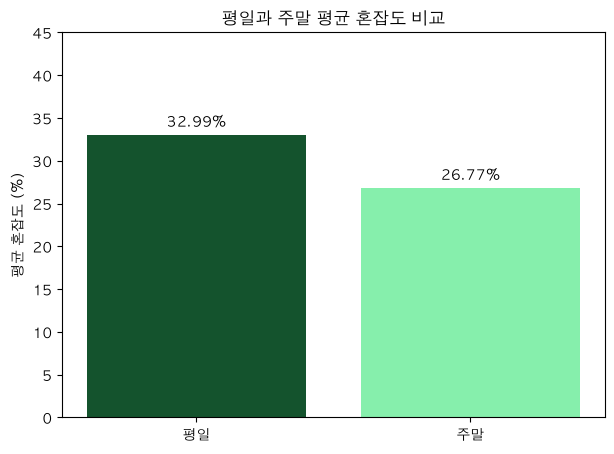

In [13]:
# 평일·주말 순서 설정
day_avg = day_avg.reindex(["평일", "주말"])

plt.figure(figsize=(7, 5))
bars = plt.bar(day_avg.index, day_avg.values, color=["#14532D", "#86EFAC"])

plt.title("평일과 주말 평균 혼잡도 비교")
plt.ylabel("평균 혼잡도 (%)")
plt.ylim(0, 45)

# 막대 위에 수치 표시
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.show()

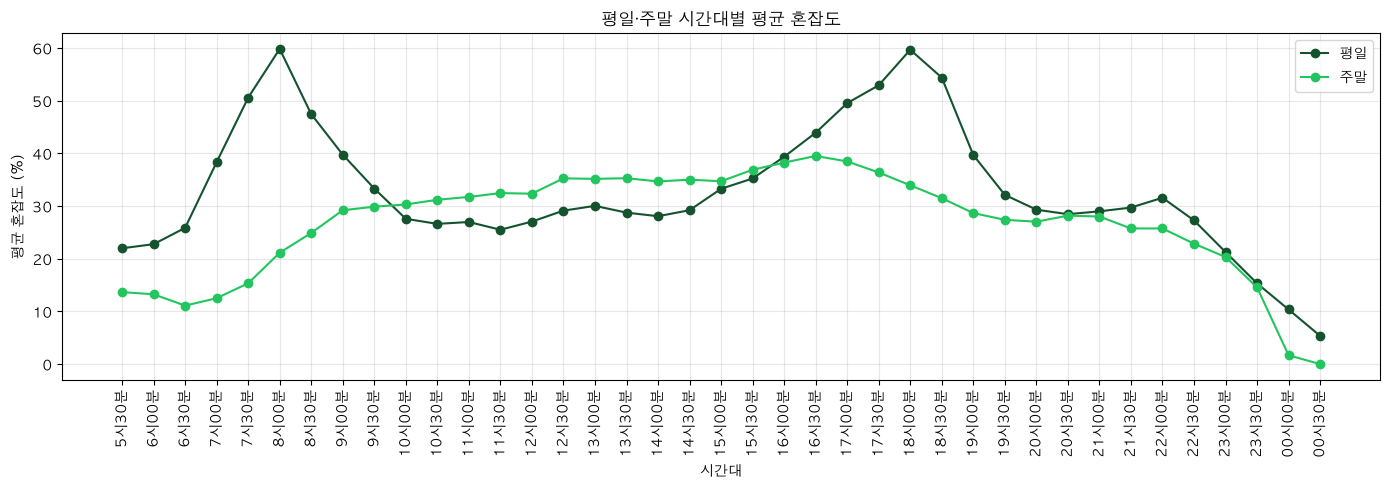

In [14]:
# 평일·주말 시간대별 평균 혼잡도
day_time_avg = df.groupby("요일유형")[time_cols].mean()

plt.figure(figsize=(14, 5))

plt.plot(time_cols, day_time_avg.loc["평일"], marker="o", label="평일", color="#14532D")

plt.plot(time_cols, day_time_avg.loc["주말"], marker="o", label="주말", color="#22C55E")

plt.title("평일·주말 시간대별 평균 혼잡도")
plt.xlabel("시간대")
plt.ylabel("평균 혼잡도 (%)")

plt.xticks(rotation=90)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# 평일과 주말 각각 가장 혼잡한 시간대
for day in ["평일", "주말"]:
    avg = day_time_avg.loc[day]

    print(f"{day} 가장 혼잡한 시간대: {avg.idxmax()}")
    print(f"평균 혼잡도: {avg.max():.2f}%")
    print()

평일 가장 혼잡한 시간대: 8시00분
평균 혼잡도: 59.82%

주말 가장 혼잡한 시간대: 16시30분
평균 혼잡도: 39.50%



In [16]:
# 호선별 평일·주말 평균 혼잡도
line_day_avg = (
    df.groupby(["호선", "요일유형"])[time_cols]
    .mean()
    .mean(axis=1)
    .unstack()
)

# 주말 - 평일 혼잡도 차이 계산
line_day_avg["혼잡도차이"] = (
    line_day_avg["주말"] - line_day_avg["평일"]
)

# 차이가 큰 순서로 정렬
line_day_avg.sort_values("혼잡도차이", ascending=False).round(2)

요일유형,주말,평일,혼잡도차이
호선,,,
6호선,23.11,25.29,-2.19
4호선,29.77,34.06,-4.29
8호선,27.91,33.14,-5.24
1호선,25.37,30.96,-5.59
5호선,24.83,30.95,-6.13
2호선,30.66,37.31,-6.65
7호선,28.86,37.13,-8.28
3호선,22.73,32.42,-9.70


### 분석 결과

- 평일의 평균 혼잡도가 주말보다 높게 나타났다.
- 평일에는 오전 출근 시간대에 혼잡도가 가장 높았다.
- 주말에는 오후 시간대에 혼잡도가 가장 높았다.
- 모든 호선에서 평일의 평균 혼잡도가 주말보다 높게 나타났다.

# 4. 혼잡도 상위 10개 역 비교

호선과 역명을 기준으로 평균 혼잡도를 계산하고, 혼잡도가 높은 상위 10개 역의 특징을 분석하였다.

환승역의 경우 동일한 역명을 가지고 있더라도 호선이 다르면 별개의 역으로 구분하였다.

### 분석 방법

- 호선·역별 평균 혼잡도 계산
- 평균 혼잡도 상위 10개 역 선정
- 상위 10개 역의 시간대별 혼잡도 비교
- 평균 혼잡도 1위 역의 최대 혼잡 시간대 확인
- 가로 막대그래프와 히트맵을 활용한 시각화

In [17]:
# 호선·역별 평균 혼잡도 계산
station_avg = df.groupby(["호선", "역명"])["평균혼잡도"].mean()

# 평균 혼잡도 상위 10개 역 선정
station_top10 = station_avg.sort_values(ascending=False).head(10)

# 결과 출력
station_top10.round(2)

호선   역명       
8호선  석촌           51.94
     송파           51.77
     잠실           49.37
4호선  남태령          48.99
     동대문          48.26
8호선  가락시장         47.46
     몽촌토성         46.97
7호선  어린이대공원       46.57
5호선  강동(하남검단산)    46.56
2호선  서초           46.30
Name: 평균혼잡도, dtype: float64

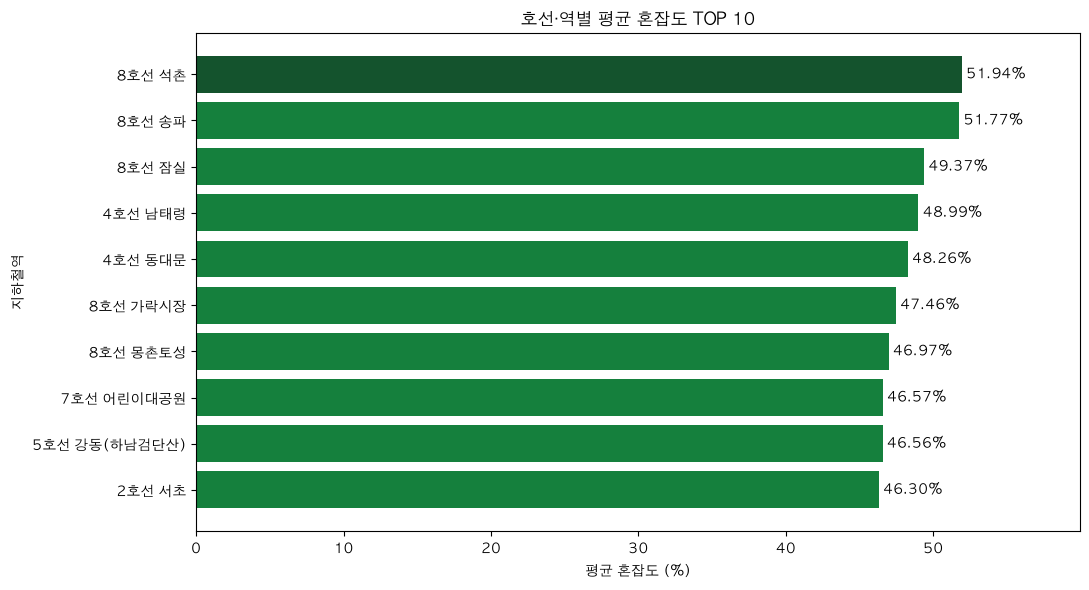

In [23]:
# 호선과 역명을 하나의 이름으로 표시
station_labels = [
    f"{line} {station}"
    for line, station in station_top10.index
]

plt.figure(figsize=(11, 6))

colors = ["#14532D"] + ["#15803D"] * 9

bars = plt.barh(station_labels, station_top10.values, color=colors)

# 혼잡도가 높은 역을 위쪽에 표시
plt.gca().invert_yaxis()

plt.title("호선·역별 평균 혼잡도 TOP 10")
plt.xlabel("평균 혼잡도 (%)")
plt.ylabel("지하철역")

# 막대 끝에 수치 표시
for bar in bars:
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

plt.xlim(0, station_top10.max() + 8)
plt.tight_layout()
plt.show()

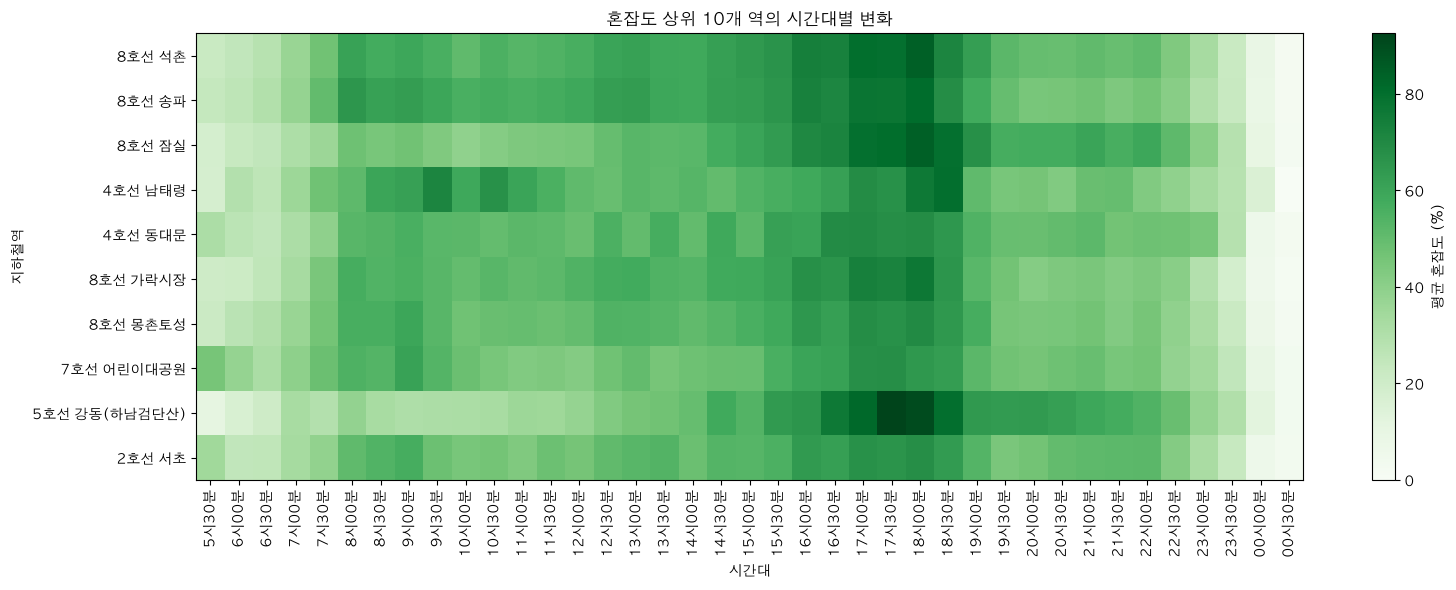

In [25]:
# 호선·역별 시간대 평균 혼잡도 계산
station_time_avg = df.groupby(["호선", "역명"])[time_cols].mean()

# 상위 10개 역만 선택
top10_time_avg = station_time_avg.loc[station_top10.index]

# 상위 10개 역의 시간대별 혼잡도 히트맵
plt.figure(figsize=(16, 6))

plt.imshow(top10_time_avg.values,
        cmap="Greens",
        aspect="auto",
        vmin=0)

# 혼잡도 색상 범례
plt.colorbar(label="평균 혼잡도 (%)")

plt.title("혼잡도 상위 10개 역의 시간대별 변화")
plt.xlabel("시간대")
plt.ylabel("지하철역")

plt.xticks(range(len(time_cols)), time_cols, rotation=90)
plt.yticks(range(len(station_labels)), station_labels)

plt.tight_layout()
plt.show()

In [26]:
# 평균 혼잡도 1위 역 선택
top_station = station_top10.index[0]

# 해당 역의 시간대별 평균 혼잡도
top_station_time = station_time_avg.loc[top_station]

print(f"가장 혼잡한 역: {top_station[0]} {top_station[1]}")
print(f"최대 혼잡 시간대: {top_station_time.idxmax()}")
print(f"해당 시간대 평균 혼잡도: {top_station_time.max():.2f}%")

가장 혼잡한 역: 8호선 석촌
최대 혼잡 시간대: 18시00분
해당 시간대 평균 혼잡도: 84.43%


### 분석 결과

- 8호선 석촌역의 평균 혼잡도가 가장 높게 나타났다.
- 혼잡도 상위 10개 역 중 8호선에 해당하는 역이 가장 많았다.
- 석촌역은 오후 6시에 평균 혼잡도가 가장 높았다.
- 히트맵을 통해 역별 혼잡 시간대와 혼잡도 변화 패턴을 비교할 수 있었다.

## 종합 분석 결과

이번 프로젝트를 통해 서울 지하철의 혼잡도가 호선, 시간대, 요일, 역에 따라 다르게 나타난다는 것을 확인하였다.

- **호선별:** 호선에 따라 평균 혼잡도에 차이가 발생하였다.
- **시간대별:** 출퇴근 시간대에 혼잡도가 집중되는 경향을 보였다.
- **요일별:** 주말보다 평일의 혼잡도가 높게 나타났다.
- **역별:** 특정 호선과 역에 높은 혼잡도가 나타났다.

이를 통해 지하철 혼잡도를 고려한 이용 시간대 선택에 도움이 되는 정보를 얻을 수 있었다.